### Step 1: Data Understanding & Preprocessing

**According to your project document, Step 1 requires:**

1. Load and explore the dataset
2. Check missing values
3. Handle missing values
4. Convert categorical variables into numerical format

In [1]:
# 1. Load the dataset
import pandas as pd
import numpy as np

df = pd.read_csv(r"E:\DATA SCIENTIST\ML\repository\project\car_price_prediction.csv")

df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [2]:
# 2. Check dataset shape
df.shape

(19237, 18)

In [3]:
# 3. Check column names
df.columns

Index(['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year',
       'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage',
       'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color',
       'Airbags'],
      dtype='object')

In [4]:
# 4. Identify target column
target = "Price"

In [5]:
# 5. Check data types
df.dtypes

ID                    int64
Price                 int64
Levy                 object
Manufacturer         object
Model                object
Prod. year            int64
Category             object
Leather interior     object
Fuel type            object
Engine volume        object
Mileage              object
Cylinders           float64
Gear box type        object
Drive wheels         object
Doors                object
Wheel                object
Color                object
Airbags               int64
dtype: object

In [6]:
# 6. Check missing values
df.isnull().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
# 8. Convert Categorical Variables
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [10]:
# 9. Final Step 1 Check
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Target Column:", "Price")

Dataset Shape: (19237, 18)
Missing Values: 0
Target Column: Price


**Observation :-**

    Dataset contains 93 cars and 28 features.
    Price is our target variable.
    Missing values were found in AirBags, Rear.seat.room, and Luggage.room.
    Missing numerical values were handled using median.
    Missing categorical values were replaced with Unknown.
    Categorical variables will be converted using One-Hot Encoding.

### Step 2 — Exploratory Data Analysis (EDA)

In [11]:
# Descriptive Statistics
df.describe()

,ID,Price,Prod. year,Cylinders,Airbags
count,1.923700e+04,1.923700e+04,19237.000000,19237.000000,19237.000000
mean,4.557654e+07,1.855593e+04,2010.912824,4.582991,6.582627
std,9.365914e+05,1.905813e+05,5.668673,1.199933,4.320168
min,2.074688e+07,1.000000e+00,1939.000000,1.000000,0.000000
25%,4.569837e+07,5.331000e+03,2009.000000,4.000000,4.000000
50%,4.577231e+07,1.317200e+04,2012.000000,4.000000,6.000000
75%,4.580204e+07,2.207500e+04,2015.000000,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,16.000000,16.000000


**Observation :-**

    Average car price is approximately 19.51.
    Average horsepower is approximately 143.83.
    Average engine size is approximately 2.67.
    Average vehicle weight is approximately 3072.90.
    Price ranges from 7.4 to 61.9.

In [12]:
# Histograms
import matplotlib.pyplot as plt

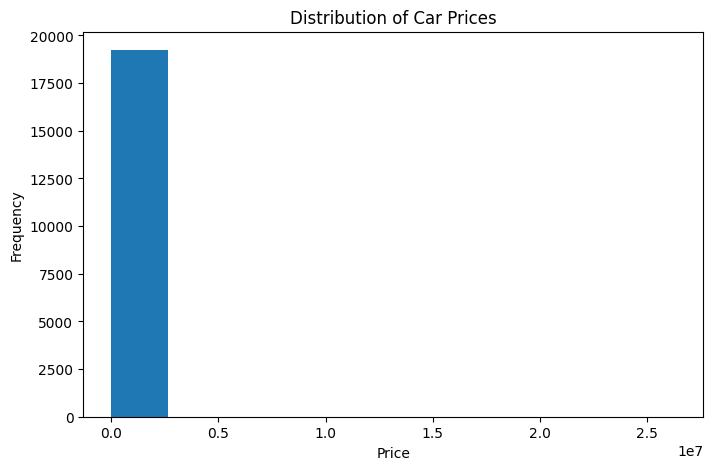

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=10)

plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of Car Prices")

plt.show()

**Observation :-**

    Most cars are concentrated in the lower-to-middle price range.
    A few cars have considerably higher prices.
    The distribution is right-skewed because of some expensive cars.

In [14]:
# Horsepower
plt.figure(figsize=(8, 5))

plt.hist(df["Horsepower"], bins=10)

plt.xlabel("Horsepower")
plt.ylabel("Frequency")
plt.title("Distribution of Horsepower")

plt.show()

KeyError: 'Horsepower'

<Figure size 800x500 with 0 Axes>

**Observation :-**

    Most cars have horsepower roughly between 80 and 200.
    A few cars have very high horsepower.
    The maximum horsepower is around 300.

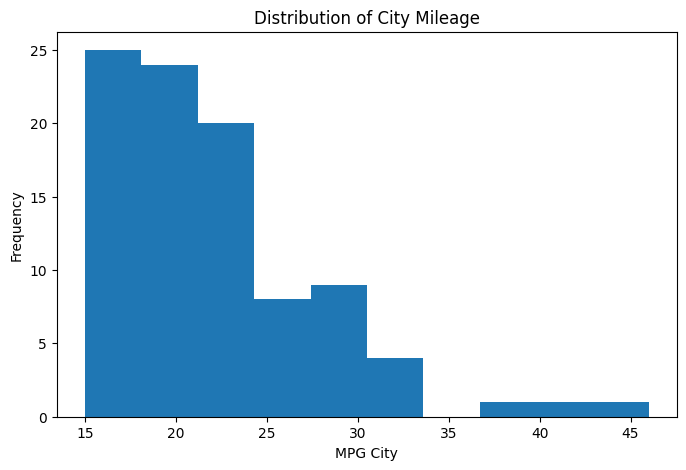

In [ ]:
# MPG.city
plt.figure(figsize=(8, 5))

plt.hist(df["MPG.city"], bins=10)

plt.xlabel("MPG City")
plt.ylabel("Frequency")
plt.title("Distribution of City Mileage")

plt.show()

**Observation :-**

    Most cars have city mileage around 18–25 MPG.
    A few cars have very high city mileage.
    The distribution has some higher-mileage observations.

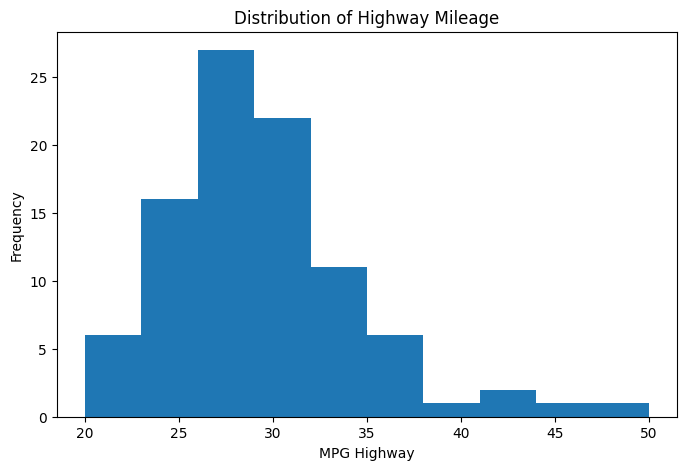

In [ ]:
# MPG.highway

plt.figure(figsize=(8, 5))

plt.hist(df["MPG.highway"], bins=10)

plt.xlabel("MPG Highway")
plt.ylabel("Frequency")
plt.title("Distribution of Highway Mileage")

plt.show()

**Observation :-**

    Most cars have highway mileage around 25–35 MPG.
    A few cars have highway mileage above 40 MPG.
    Most observations are concentrated in the middle range.

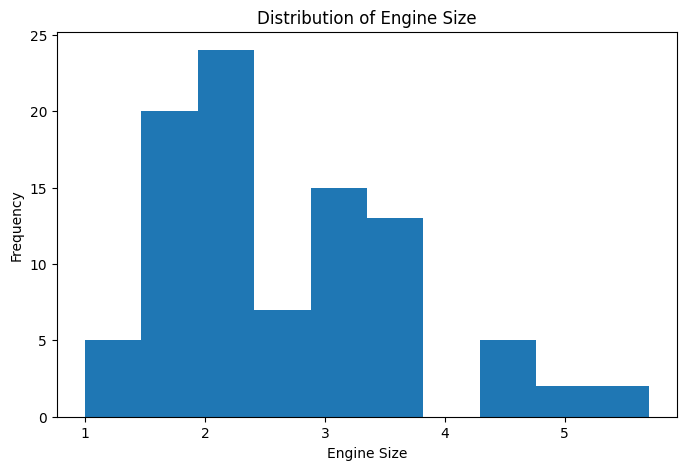

In [ ]:
# EngineSize
plt.figure(figsize=(8, 5))

plt.hist(df["EngineSize"], bins=10)

plt.xlabel("Engine Size")
plt.ylabel("Frequency")
plt.title("Distribution of Engine Size")

plt.show()

**Observation :-**

    Most cars have engine sizes between approximately 1.5 and 4.0.
    Smaller engines are common.
    A few cars have very large engines.

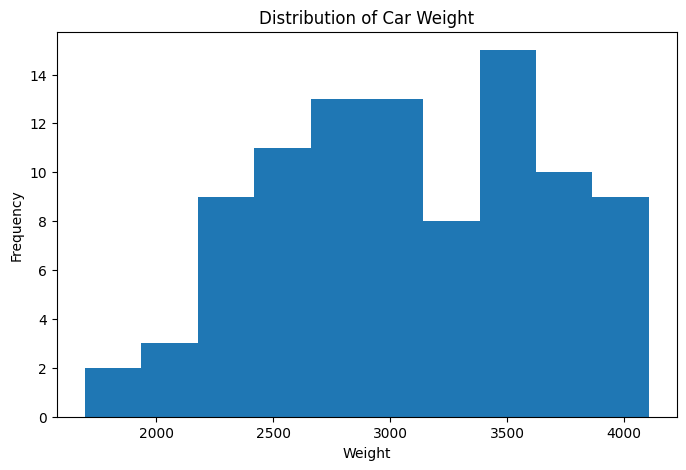

In [ ]:
# Weight

plt.figure(figsize=(8, 5))

plt.hist(df["Weight"], bins=10)

plt.xlabel("Weight")
plt.ylabel("Frequency")
plt.title("Distribution of Car Weight")

plt.show()

**Observation :-**

    Most cars weigh approximately 2,300–3,800 pounds.
    Very lightweight and very heavy cars are less common.
    The dataset contains some cars weighing more than 4,000 pounds.

### Scatter Plots

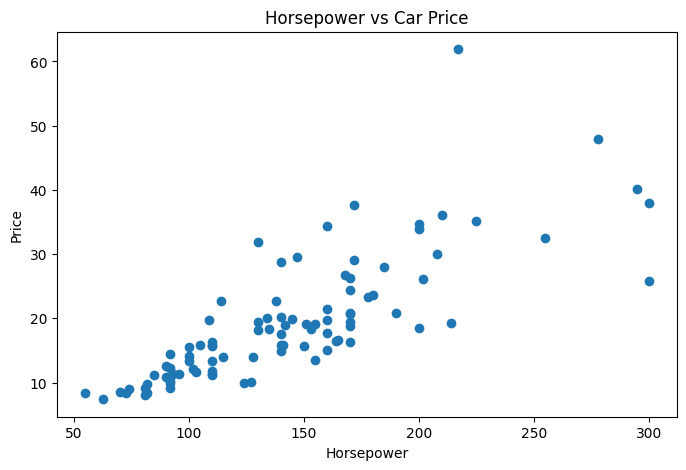

In [ ]:
# Horsepower vs Price
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["Horsepower"], df["Price"])

plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.title("Horsepower vs Car Price")

plt.show()

**Observation :-**

    There is a positive relationship between horsepower and price.
    As horsepower increases, car price generally increases.
    High-performance cars tend to have higher prices.

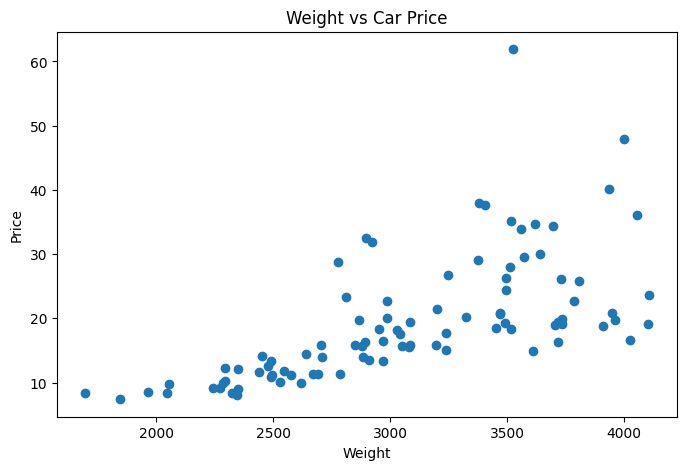

In [ ]:
# Weight vs Price
plt.figure(figsize=(8, 5))

plt.scatter(df["Weight"], df["Price"])

plt.xlabel("Weight")
plt.ylabel("Price")
plt.title("Weight vs Car Price")

plt.show()

**Observation :-**

    There is a positive relationship between weight and price.
    Heavier cars generally tend to have higher prices.
    The relationship is not perfectly linear because other factors also affect price.

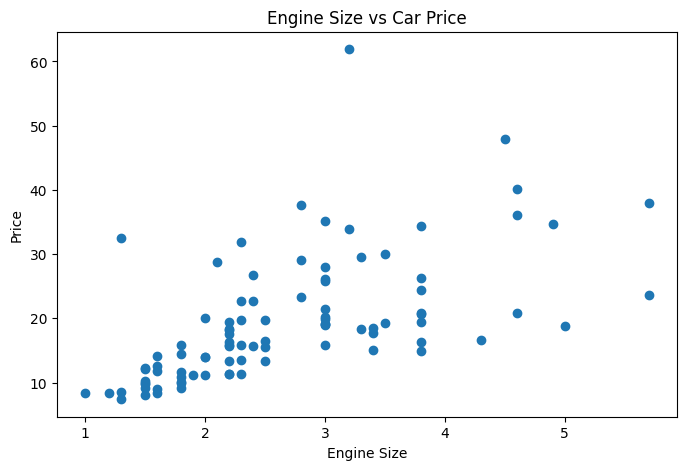

In [ ]:
# Engine Size vs Price
plt.figure(figsize=(8, 5))

plt.scatter(df["EngineSize"], df["Price"])

plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.title("Engine Size vs Car Price")

plt.show()

**Observation :-**

    There is a generally positive relationship.
    Cars with larger engines tend to have higher prices.
    Some variation exists because price also depends on other features.

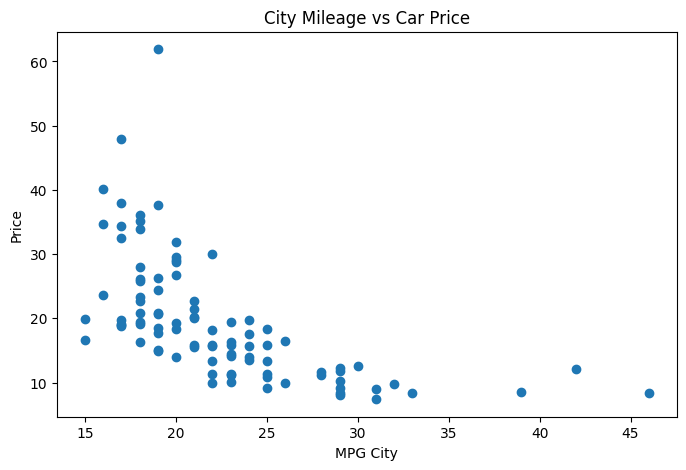

In [ ]:
# MPG.city vs Price
plt.figure(figsize=(8, 5))

plt.scatter(df["MPG.city"], df["Price"])

plt.xlabel("MPG City")
plt.ylabel("Price")
plt.title("City Mileage vs Car Price")

plt.show()

**Observation :-**

    There is a negative relationship.
    Cars with higher city mileage generally have lower prices in this dataset.
    Lower-MPG cars tend to appear at higher price levels.

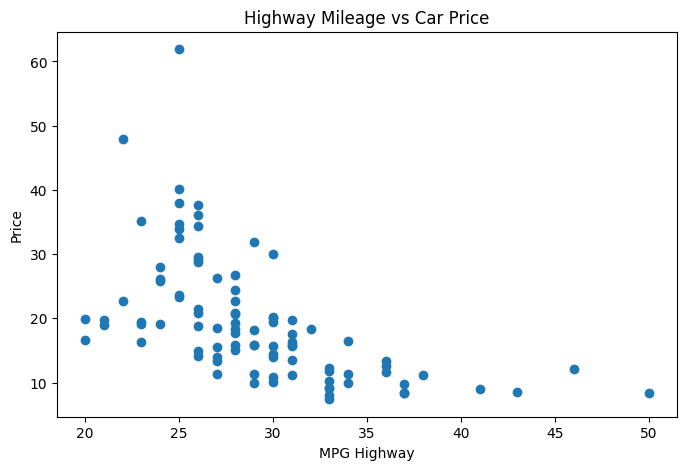

In [ ]:
# MPG.highway vs Price
plt.figure(figsize=(8, 5))

plt.scatter(df["MPG.highway"], df["Price"])

plt.xlabel("MPG Highway")
plt.ylabel("Price")
plt.title("Highway Mileage vs Car Price")

plt.show()

**Observation :-**

    There is a negative relationship between highway mileage and price.
    Higher highway MPG generally corresponds to lower prices in this dataset.

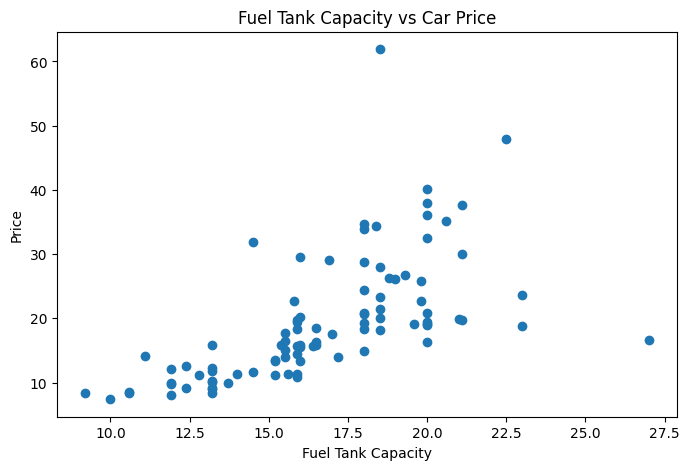

In [ ]:
# Fuel Tank Capacity vs Price
plt.figure(figsize=(8, 5))

plt.scatter(df["Fuel.tank.capacity"], df["Price"])

plt.xlabel("Fuel Tank Capacity")
plt.ylabel("Price")
plt.title("Fuel Tank Capacity vs Car Price")

plt.show()

**Observation :-**

    There is generally a positive relationship.
    Cars with larger fuel tanks tend to have higher prices.

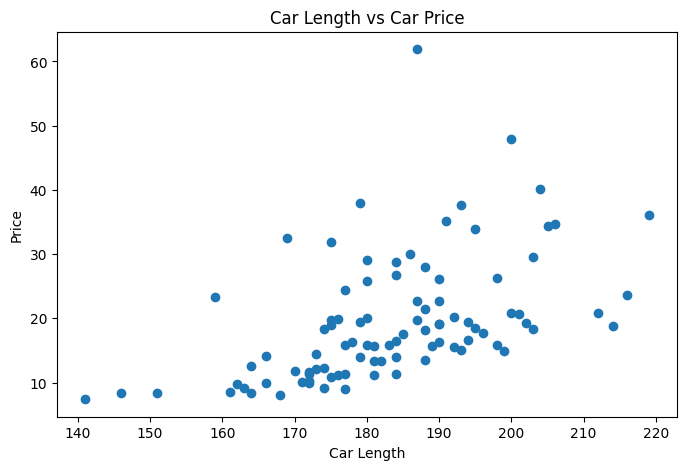

In [ ]:
# Length vs Price
plt.figure(figsize=(8, 5))

plt.scatter(df["Length"], df["Price"])

plt.xlabel("Car Length")
plt.ylabel("Price")
plt.title("Car Length vs Car Price")

plt.show()

**Observation :-**

    There is a moderate positive relationship.
    Longer cars generally tend to have higher prices.

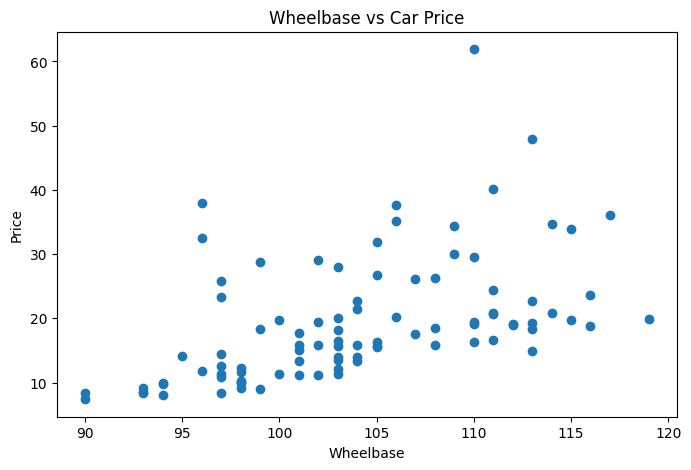

In [ ]:
# Wheelbase vs Price
plt.figure(figsize=(8, 5))

plt.scatter(df["Wheelbase"], df["Price"])

plt.xlabel("Wheelbase")
plt.ylabel("Price")
plt.title("Wheelbase vs Car Price")

plt.show()

**Observation :-**

    There is a moderate positive relationship.
    Cars with larger wheelbases generally tend to have higher prices.

### Box Plot

<Figure size 900x500 with 0 Axes>

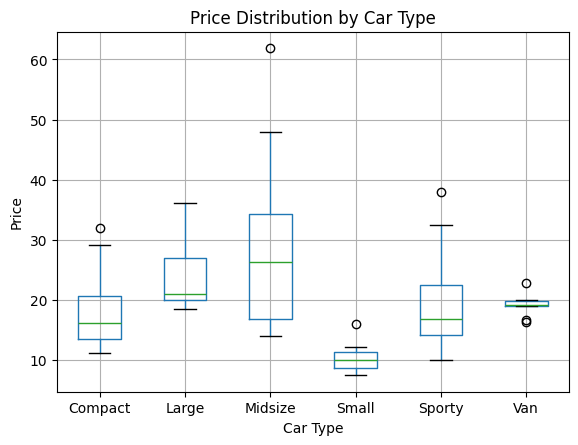

<Figure size 800x500 with 0 Axes>

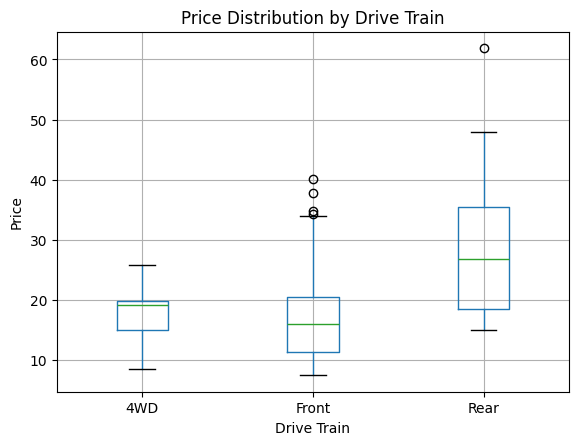

<Figure size 900x500 with 0 Axes>

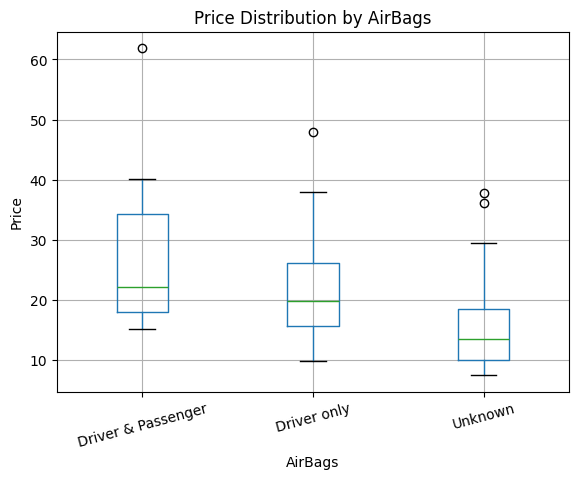

In [ ]:

# Price vs Type
plt.figure(figsize=(9, 5))
df.boxplot(column="Price", by="Type")
plt.xlabel("Car Type")
plt.ylabel("Price")
plt.title("Price Distribution by Car Type")
plt.suptitle("")
plt.show()


# Price vs DriveTrain
plt.figure(figsize=(8, 5))
df.boxplot(column="Price", by="DriveTrain")
plt.xlabel("Drive Train")
plt.ylabel("Price")
plt.title("Price Distribution by Drive Train")
plt.suptitle("")
plt.show()


# Price vs AirBags
plt.figure(figsize=(9, 5))
df.boxplot(column="Price", by="AirBags")
plt.xlabel("AirBags")
plt.ylabel("Price")
plt.title("Price Distribution by AirBags")
plt.suptitle("")
plt.xticks(rotation=15)
plt.show()

### Correlation Heatmap

In [ ]:

numeric_df = df.select_dtypes(include="number")

numeric_df.head()

,id,Min.Price,Price,Max.Price,MPG.city,MPG.highway,EngineSize,Horsepower,RPM,Rev.per.mile,Fuel.tank.capacity,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight
0,1,12.9,15.9,18.8,25,31,1.8,140,6300,2890,13.2,5,177,102,68,37,26.5,11.0,2705
1,2,29.2,33.9,38.7,18,25,3.2,200,5500,2335,18.0,5,195,115,71,38,30.0,15.0,3560
2,3,25.9,29.1,32.3,20,26,2.8,172,5500,2280,16.9,5,180,102,67,37,28.0,14.0,3375
3,4,30.8,37.7,44.6,19,26,2.8,172,5500,2535,21.1,6,193,106,70,37,31.0,17.0,3405
4,5,23.7,30.0,36.2,22,30,3.5,208,5700,2545,21.1,4,186,109,69,39,27.0,13.0,3640


In [ ]:
correlation = numeric_df.corr()

correlation

,id,Min.Price,Price,Max.Price,MPG.city,MPG.highway,EngineSize,Horsepower,RPM,Rev.per.mile,Fuel.tank.capacity,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight
id,1.000000,-0.144463,-0.137277,-0.126567,0.161808,0.137317,-0.338286,-0.233012,0.167772,0.226389,-0.179034,-0.142252,-0.277911,-0.244888,-0.293592,-0.275867,-0.125304,-0.160756,-0.220525
Min.Price,-0.144463,1.000000,0.970601,0.906756,-0.622875,-0.579966,0.645488,0.802444,-0.042598,-0.470395,0.635369,0.061236,0.553859,0.516758,0.492878,0.428603,0.356926,0.396940,0.666554
Price,-0.137277,0.970601,1.000000,0.981580,-0.594562,-0.560680,0.597425,0.788218,-0.004955,-0.426395,0.619480,0.057860,0.503628,0.500864,0.456028,0.392590,0.297898,0.355827,0.647179
Max.Price,-0.126567,0.906756,0.981580,1.000000,-0.547811,-0.522561,0.535012,0.744445,0.025015,-0.374024,0.581294,0.053216,0.442933,0.467501,0.408414,0.347785,0.238249,0.308203,0.605142
MPG.city,0.161808,-0.622875,-0.594562,-0.547811,1.000000,0.943936,-0.710003,-0.672636,0.363045,0.695857,-0.813144,-0.416856,-0.666239,-0.667108,-0.720534,-0.666389,-0.378071,-0.466621,-0.843139
MPG.highway,0.137317,-0.579966,-0.560680,-0.522561,0.943936,1.000000,-0.626795,-0.619044,0.313469,0.587497,-0.786039,-0.466386,-0.542897,-0.615384,-0.640359,-0.593683,-0.362379,-0.333507,-0.810658
EngineSize,-0.338286,0.645488,0.597425,0.535012,-0.710003,-0.626795,1.000000,0.732120,-0.547898,-0.824009,0.759306,0.372721,0.780283,0.732484,0.867110,0.778464,0.471733,0.620915,0.845075
Horsepower,-0.233012,0.802444,0.788218,0.744445,-0.672636,-0.619044,0.732120,1.000000,0.036688,-0.600314,0.711790,0.009264,0.550865,0.486854,0.644413,0.561216,0.230654,0.331115,0.738798
RPM,0.167772,-0.042598,-0.004955,0.025015,0.363045,0.313469,-0.547898,0.036688,1.000000,0.494764,-0.333345,-0.467138,-0.441249,-0.467812,-0.539721,-0.505651,-0.335709,-0.484468,-0.427931
Rev.per.mile,0.226389,-0.470395,-0.426395,-0.374024,0.695857,0.587497,-0.824009,-0.600314,0.494764,1.000000,-0.609710,-0.334976,-0.690233,-0.636824,-0.780460,-0.733160,-0.368190,-0.559548,-0.735264


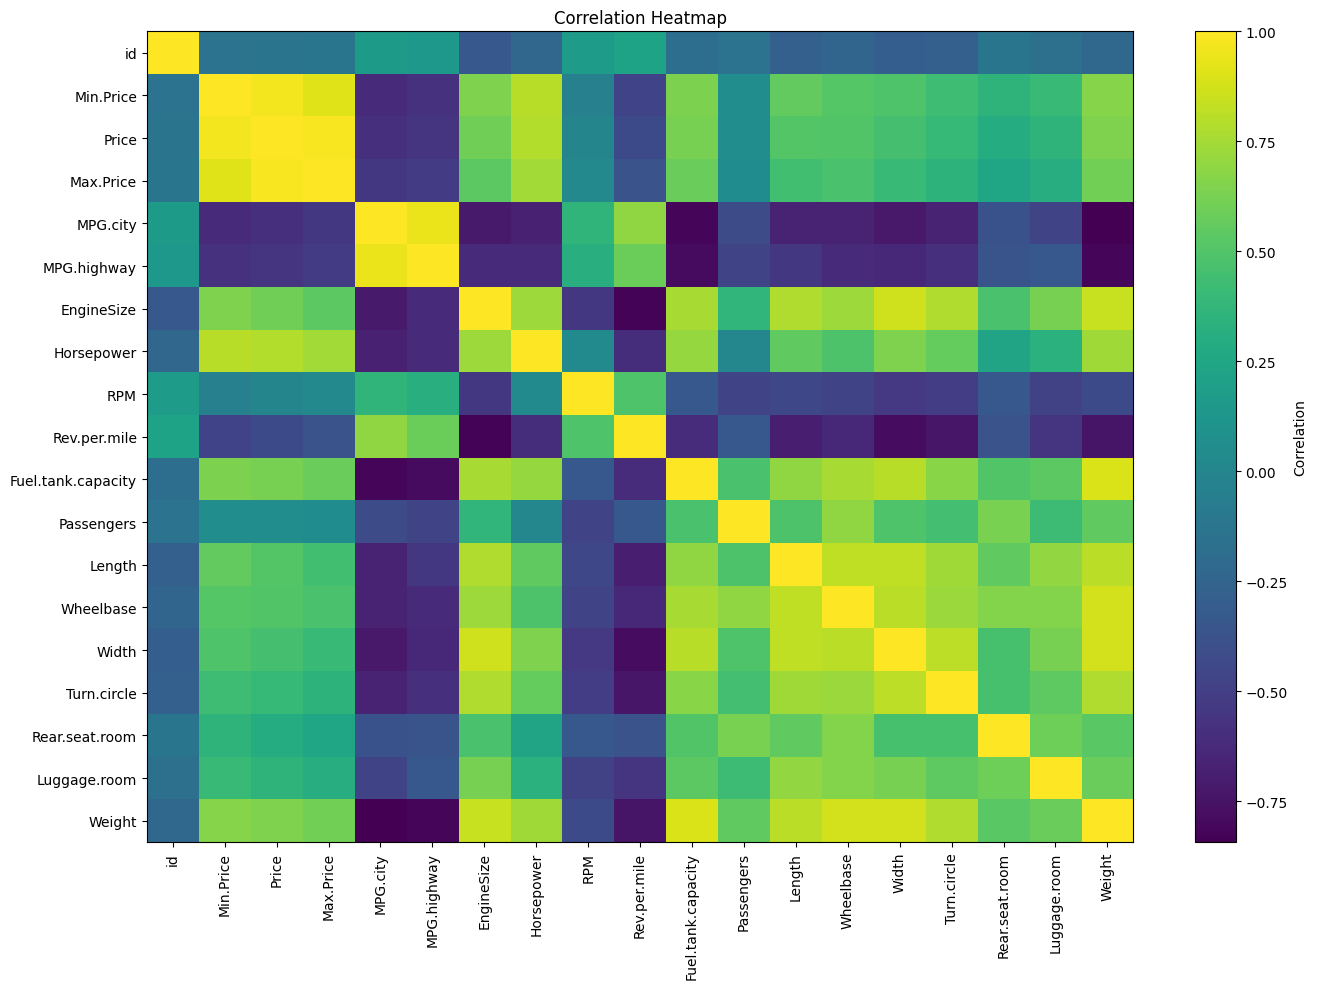

In [ ]:
# Create the correlation heatmap
plt.figure(figsize=(14, 10))

plt.imshow(correlation, aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.show()

In [ ]:
# Find Correlation with Price
price_correlation = correlation["Price"].sort_values(
    ascending=False
)

price_correlation

Price                 1.000000
Max.Price             0.981580
Min.Price             0.970601
Horsepower            0.788218
Weight                0.647179
Fuel.tank.capacity    0.619480
EngineSize            0.597425
Length                0.503628
Wheelbase             0.500864
Width                 0.456028
Turn.circle           0.392590
Luggage.room          0.355827
Rear.seat.room        0.297898
Passengers            0.057860
RPM                  -0.004955
id                   -0.137277
Rev.per.mile         -0.426395
MPG.highway          -0.560680
MPG.city             -0.594562
Name: Price, dtype: float64

In [ ]:
price_correlation = (
    correlation["Price"]
    .sort_values(ascending=False)
)

print(price_correlation)

Price                 1.000000
Max.Price             0.981580
Min.Price             0.970601
Horsepower            0.788218
Weight                0.647179
Fuel.tank.capacity    0.619480
EngineSize            0.597425
Length                0.503628
Wheelbase             0.500864
Width                 0.456028
Turn.circle           0.392590
Luggage.room          0.355827
Rear.seat.room        0.297898
Passengers            0.057860
RPM                  -0.004955
id                   -0.137277
Rev.per.mile         -0.426395
MPG.highway          -0.560680
MPG.city             -0.594562
Name: Price, dtype: float64


In [ ]:
# Top Features Related to Price
price_corr = correlation["Price"].drop("Price")

top_features = price_corr.abs().sort_values(
    ascending=False
).head(10)

top_features

Max.Price             0.981580
Min.Price             0.970601
Horsepower            0.788218
Weight                0.647179
Fuel.tank.capacity    0.619480
EngineSize            0.597425
MPG.city              0.594562
MPG.highway           0.560680
Length                0.503628
Wheelbase             0.500864
Name: Price, dtype: float64

### Step 3 — Model Development

1. Split the dataset into training and testing sets.
2. Build a Linear Regression model.
3. Train the model.
4. Test it on unseen data

In [ ]:
# Define Features and Target
X = df.drop("Price", axis=1)

y = df["Price"]

In [ ]:
X.head()

,id,Manufacturer,Model,Type,Min.Price,Max.Price,MPG.city,MPG.highway,AirBags,DriveTrain,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
0,1,Acura,Integra,Small,12.9,18.8,25,31,Unknown,Front,...,5,177,102,68,37,26.5,11.0,2705,non-USA,Acura Integra
1,2,Acura,Legend,Midsize,29.2,38.7,18,25,Driver & Passenger,Front,...,5,195,115,71,38,30.0,15.0,3560,non-USA,Acura Legend
2,3,Audi,90,Compact,25.9,32.3,20,26,Driver only,Front,...,5,180,102,67,37,28.0,14.0,3375,non-USA,Audi 90
3,4,Audi,100,Midsize,30.8,44.6,19,26,Unknown,Front,...,6,193,106,70,37,31.0,17.0,3405,non-USA,Audi 100
4,5,BMW,535i,Midsize,23.7,36.2,22,30,Driver only,Rear,...,4,186,109,69,39,27.0,13.0,3640,non-USA,BMW 535i


In [ ]:
y.head()

0    15.9
1    33.9
2    29.1
3    37.7
4    30.0
Name: Price, dtype: float64

In [ ]:
# Remove Price-Related Columns
X = X.drop(["Min.Price", "Max.Price"], axis=1)

In [ ]:
X.head()

,id,Manufacturer,Model,Type,MPG.city,MPG.highway,AirBags,DriveTrain,Cylinders,EngineSize,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
0,1,Acura,Integra,Small,25,31,Unknown,Front,4,1.8,...,5,177,102,68,37,26.5,11.0,2705,non-USA,Acura Integra
1,2,Acura,Legend,Midsize,18,25,Driver & Passenger,Front,6,3.2,...,5,195,115,71,38,30.0,15.0,3560,non-USA,Acura Legend
2,3,Audi,90,Compact,20,26,Driver only,Front,6,2.8,...,5,180,102,67,37,28.0,14.0,3375,non-USA,Audi 90
3,4,Audi,100,Midsize,19,26,Unknown,Front,6,2.8,...,6,193,106,70,37,31.0,17.0,3405,non-USA,Audi 100
4,5,BMW,535i,Midsize,22,30,Driver only,Rear,4,3.5,...,4,186,109,69,39,27.0,13.0,3640,non-USA,BMW 535i


In [ ]:
# Identify Numerical and Categorical Features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

In [ ]:
print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['id', 'MPG.city', 'MPG.highway', 'EngineSize', 'Horsepower', 'RPM', 'Rev.per.mile', 'Fuel.tank.capacity', 'Passengers', 'Length', 'Wheelbase', 'Width', 'Turn.circle', 'Rear.seat.room', 'Luggage.room', 'Weight']

Categorical Features:
['Manufacturer', 'Model', 'Type', 'AirBags', 'DriveTrain', 'Cylinders', 'Man.trans.avail', 'Origin', 'Make']


In [ ]:
# Import Preprocessing Tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
# Create Categorical Encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [ ]:
# Create Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            encoder,
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [ ]:
# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:
# Check the sizes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (74, 25)
X_test: (19, 25)
y_train: (74,)
y_test: (19,)


In [ ]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [ ]:
# Create ML Pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

In [ ]:
# Train the Model
pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
# Make Predictions
y_pred = pipeline.predict(X_test)

In [ ]:
print(y_pred)

[18.20980355  9.69552865 22.62622977  8.80323737 14.96487589 17.38574595
 14.50879214 19.41407739 39.91998321 14.55095083 13.33854589 23.41297347
 29.84092655 33.87525276 12.19842585 35.27847413 29.40998132  4.77957892
 34.89315208]


In [ ]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison

,Actual Price,Predicted Price
0,19.8,18.209804
1,9.2,9.695529
2,19.1,22.626230
3,9.0,8.803237
4,15.9,14.964876
5,15.6,17.385746
6,12.5,14.508792
7,13.5,19.414077
8,40.1,39.919983
9,10.0,14.550951


### Model Evaluation

In [ ]:
# Import Evaluation Metrics
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [ ]:
# Calculate R² Score
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.7990579180166968


In [ ]:
# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 3.4181742647881523


In [ ]:
# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 19.19006902213331


In [ ]:
# Calculate RMSE
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 4.380647100844042


In [ ]:
# Create an Evaluation Table
evaluation = pd.DataFrame({
    "Metric": ["R² Score", "MAE", "MSE", "RMSE"],
    "Value": [r2, mae, mse, rmse]
})

evaluation

,Metric,Value
0,R² Score,0.799058
1,MAE,3.418174
2,MSE,19.190069
3,RMSE,4.380647


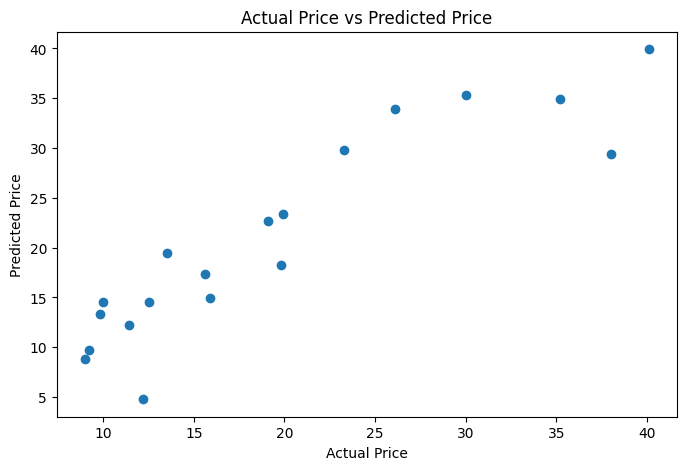

In [ ]:
# Actual vs Predicted Prices
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Price vs Predicted Price")

plt.show()

**Observation :-**

    Points closer to a diagonal relationship indicate better predictions.
    Large distances between actual and predicted values indicate larger prediction errors.
    The overall pattern helps us visually judge the model's performance.

### Step 5 — Final Deliverables